# 1. Introduction

In this notebook, we build an explainable customer segmentation pipeline for the FinSight AI project.

**What is Customer Segmentation?**
Customer segmentation is the process of dividing a customer base into distinct groups (clusters) that share similar characteristics or behaviors.

**Why is it useful in financial analytics?**
It allows financial institutions to understand different customer profiles, tailor products, personalize marketing, assess risk profiles, and monitor abnormal shifts in group behaviors over time.

**Why Customer-Level Aggregation is needed:**
Our raw dataset is transactional. A single customer may have hundreds of transactions. To cluster *customers*, we first need to aggregate these transactions into single rows per customer, creating features that represent their overall behavior (e.g., total spend, transaction frequency, anomaly rate).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

# 2. Load and Validate Data

We load the validated transaction dataset from Stage 3, which includes anomaly features.

In [2]:
# Try to load the anomalies dataset. If not found, load the cleaned dataset.
import os
file_path = '../data/processed/transactions_with_anomalies.csv'

if not os.path.exists(file_path):
    print(f"Warning: {file_path} not found. Attempting to load transactions_cleaned.csv instead.")
    file_path = '../data/processed/transactions_cleaned.csv'

df = pd.read_csv(file_path)
df['transaction_date'] = pd.to_datetime(df['transaction_date'])

print("--- Data Validation ---")
print(f"Row Count: {len(df):,}")
print(f"Missing Values: \n{df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"Customer Count: {df['customer_id'].nunique():,}")
display(df.info())

--- Data Validation ---
Row Count: 100,000
Missing Values: 
0
Duplicate Rows: 0
Customer Count: 9,999
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   transaction_id              100000 non-null  object        
 1   customer_id                 100000 non-null  object        
 2   account_id                  100000 non-null  object        
 3   transaction_date            100000 non-null  datetime64[ns]
 4   amount                      100000 non-null  float64       
 5   transaction_type            100000 non-null  object        
 6   merchant_category           100000 non-null  object        
 7   payment_method              100000 non-null  object        
 8   location                    100000 non-null  object        
 9   status                      100000 non-null  object        
 10  iqr

None

# 3. Customer-Level Feature Engineering

We aggregate the transactions by `customer_id`. The customer ID acts strictly as a grouping key and will NOT be used as a machine learning feature.

In [3]:
# Ensure anomaly columns exist, even if falling back to a non-anomaly dataset
if 'ml_anomaly' not in df.columns:
    df['ml_anomaly'] = 0
if 'iqr_anomaly' not in df.columns:
    df['iqr_anomaly'] = 0

# Aggregate by customer_id
customer_df = df.groupby('customer_id').agg(
    transaction_count=('transaction_id', 'count'),
    total_spend=('amount', 'sum'),
    average_transaction=('amount', 'mean'),
    median_transaction=('amount', 'median'),
    std_transaction=('amount', 'std'),
    minimum_transaction=('amount', 'min'),
    maximum_transaction=('amount', 'max'),
    unique_merchant_categories=('merchant_category', 'nunique'),
    unique_payment_methods=('payment_method', 'nunique'),
    unique_locations=('location', 'nunique'),
    potential_anomaly_count=('ml_anomaly', 'sum'),
    # Additional behavioral counts (assuming 'transaction_type' has these values, otherwise 0)
    purchase_count=('transaction_type', lambda x: (x == 'Purchase').sum() if 'Purchase' in x.values else (x == 'purchase').sum()),
    transfer_count=('transaction_type', lambda x: (x == 'Transfer').sum() if 'Transfer' in x.values else (x == 'transfer').sum()),
    withdrawal_count=('transaction_type', lambda x: (x == 'Withdrawal').sum() if 'Withdrawal' in x.values else (x == 'withdrawal').sum())
).reset_index()

# Handle missing/zero std dev safely
customer_df['std_transaction'] = customer_df['std_transaction'].fillna(0)

# Calculate anomaly rate
customer_df['anomaly_rate'] = customer_df['potential_anomaly_count'] / customer_df['transaction_count']

# Duration of relationship in dataset (months)
date_range_per_cust = df.groupby('customer_id')['transaction_date'].agg(['min', 'max'])
date_range_per_cust['months_active'] = (date_range_per_cust['max'] - date_range_per_cust['min']).dt.days / 30.0
date_range_per_cust['months_active'] = date_range_per_cust['months_active'].replace(0, 1) # Avoid division by zero

customer_df = customer_df.merge(date_range_per_cust['months_active'], on='customer_id', how='left')
customer_df['avg_spend_per_month'] = customer_df['total_spend'] / customer_df['months_active']
customer_df['transaction_frequency_per_month'] = customer_df['transaction_count'] / customer_df['months_active']

display(customer_df.head())

,customer_id,transaction_count,total_spend,average_transaction,median_transaction,std_transaction,minimum_transaction,maximum_transaction,unique_merchant_categories,unique_payment_methods,unique_locations,potential_anomaly_count,purchase_count,transfer_count,withdrawal_count,anomaly_rate,months_active,avg_spend_per_month,transaction_frequency_per_month
0,c-00001,9,706.43,78.492222,41.670,64.525755,23.26,206.91,5,2,2,0,6,1,2,0.0,8.400000,84.098810,1.071429
1,c-00002,10,357.80,35.780000,26.805,32.781573,3.97,114.75,6,3,2,0,6,4,0,0.0,11.733333,30.494318,0.852273
2,c-00003,5,512.64,102.528000,121.650,50.913978,39.89,161.07,4,2,1,0,4,1,0,0.0,13.066667,39.232653,0.382653
3,c-00004,8,254.58,31.822500,29.445,24.541107,2.85,73.30,5,3,1,0,6,1,1,0.0,10.866667,23.427607,0.736196
4,c-00005,6,78.88,13.146667,12.035,8.862053,2.17,28.52,3,2,1,0,4,2,0,0.0,9.266667,8.512230,0.647482


# 4. Feature Distribution Analysis

Visualizing the distributions of key customer features to understand skewness and variance.

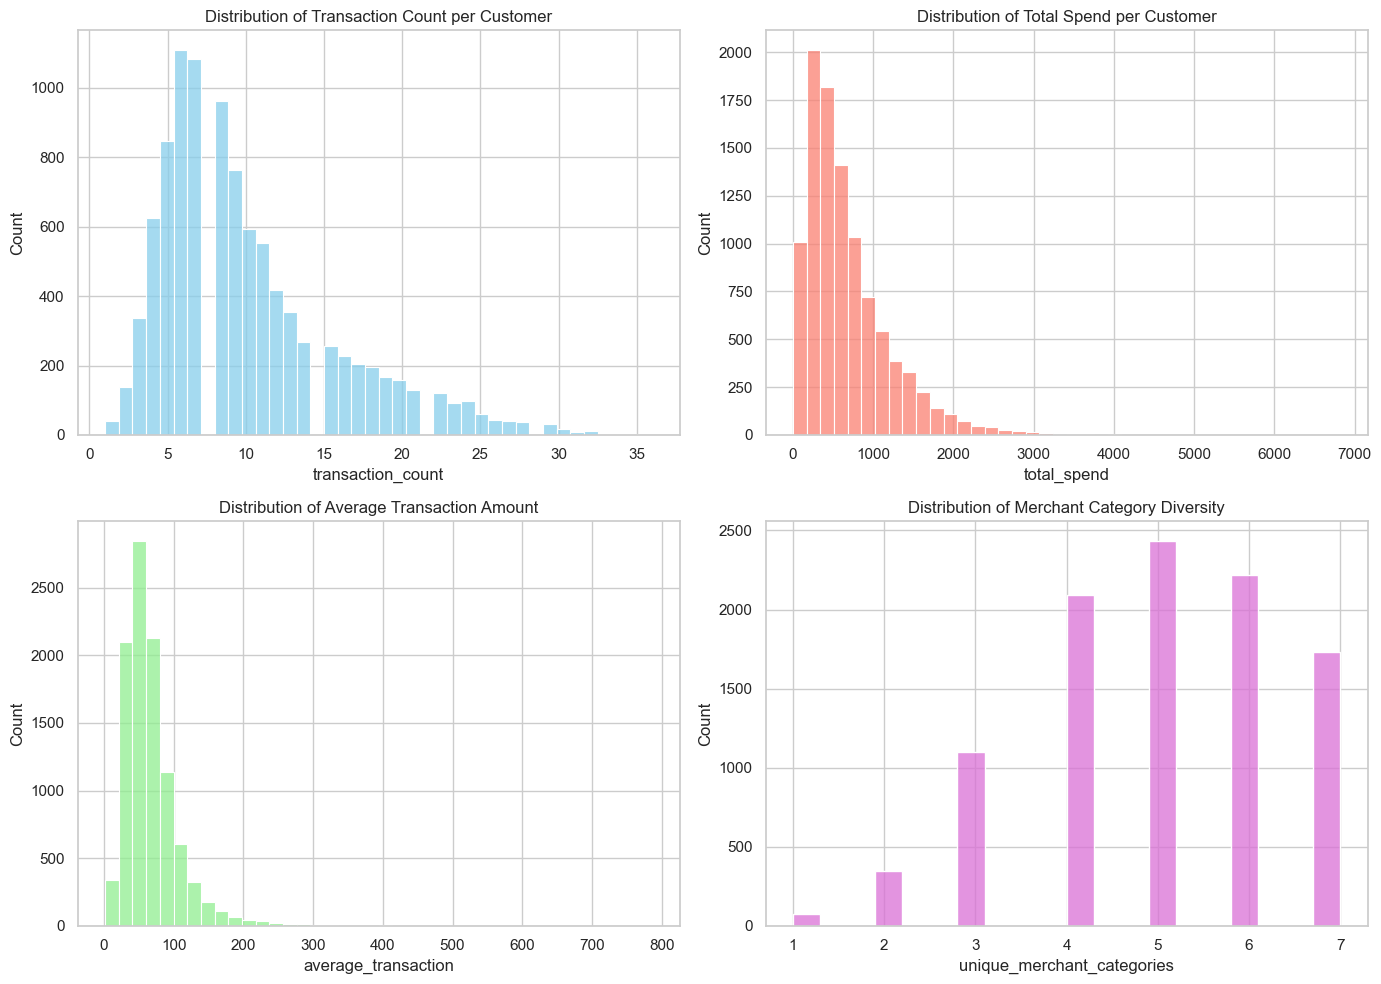

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(customer_df['transaction_count'], bins=40, ax=axes[0,0], color='skyblue')
axes[0,0].set_title('Distribution of Transaction Count per Customer')

sns.histplot(customer_df['total_spend'], bins=40, ax=axes[0,1], color='salmon')
axes[0,1].set_title('Distribution of Total Spend per Customer')

sns.histplot(customer_df['average_transaction'], bins=40, ax=axes[1,0], color='lightgreen')
axes[1,0].set_title('Distribution of Average Transaction Amount')

sns.histplot(customer_df['unique_merchant_categories'], bins=20, ax=axes[1,1], color='orchid')
axes[1,1].set_title('Distribution of Merchant Category Diversity')

plt.tight_layout()
plt.show()

# 5. Feature Selection

We select meaningful behavioral features for clustering. We avoid identifiers. 
Selected features:
- `total_spend`: Represents overall monetary value of the customer.
- `transaction_count`: Represents engagement frequency.
- `average_transaction`: Represents the typical scale of their activity.
- `std_transaction`: Represents spending consistency/volatility.
- `unique_merchant_categories`: Represents lifestyle and breadth of usage.
- `unique_payment_methods`: Represents digital savviness or financial complexity.
- `anomaly_rate`: Represents the likelihood of engaging in unusual activities.

In [5]:
features = [
    'total_spend', 
    'transaction_count', 
    'average_transaction', 
    'std_transaction', 
    'unique_merchant_categories', 
    'unique_payment_methods',
    'anomaly_rate'
]

X = customer_df[features]

# 6. Feature Scaling

K-Means relies on distance metrics (Euclidean distance). If features are on different scales (e.g., total spend in thousands vs unique categories in single digits), the model will be entirely dominated by the features with larger magnitudes.

We use `StandardScaler` to give each feature a mean of 0 and a variance of 1.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(X_scaled, columns=features)
display(scaled_df.head())

,total_spend,transaction_count,average_transaction,std_transaction,unique_merchant_categories,unique_payment_methods,anomaly_rate
0,0.054618,-0.174597,0.248548,-0.221174,-0.003539,-1.115384,-0.546801
1,-0.592270,-0.000174,-0.737959,-0.604340,0.704245,0.111538,-0.546801
2,-0.304962,-0.872289,0.803693,-0.385474,-0.711323,-1.115384,-0.546801
3,-0.783796,-0.349020,-0.829364,-0.703806,-0.003539,0.111538,-0.546801
4,-1.109810,-0.697866,-1.260712,-0.893059,-1.419107,-1.115384,-0.546801


# 7. Determine Number of Clusters

We evaluate a range of K values (from 2 to 8) using the Elbow Method (Inertia) and Silhouette Score. We then programmatically select a reasonable K based on the best silhouette score, rather than arbitrarily forcing K=4.

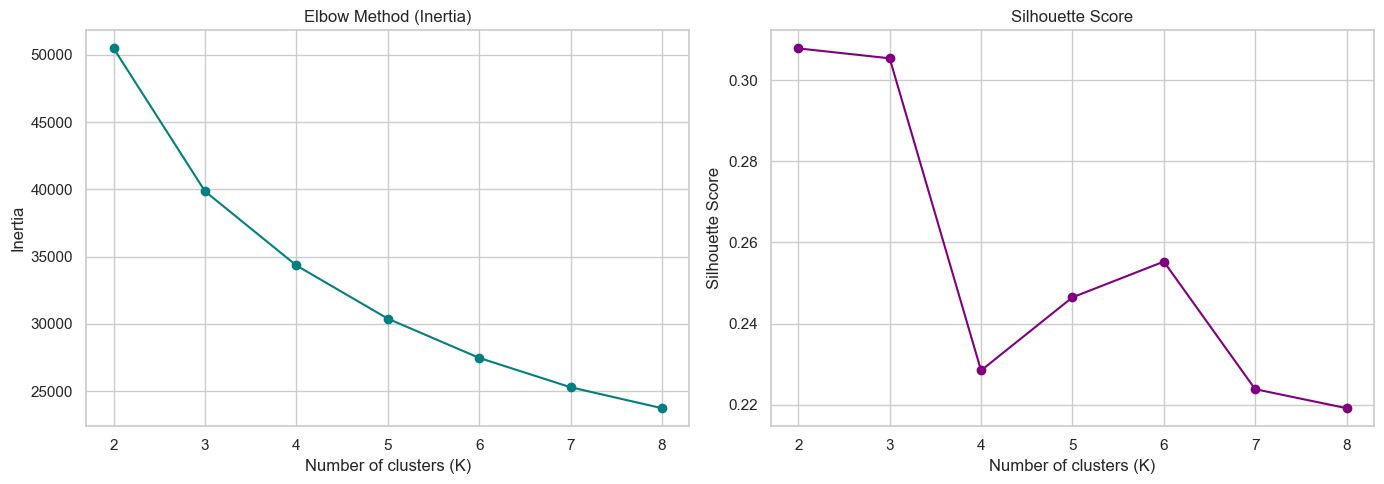

Based on the highest silhouette score, the optimal number of clusters is automatically selected as: K = 2


In [7]:
inertia = []
silhouette_scores = []
K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertia, marker='o', color='teal')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, silhouette_scores, marker='o', color='purple')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

# Programmatic Selection
best_k = K_range[np.argmax(silhouette_scores)]
print(f"Based on the highest silhouette score, the optimal number of clusters is automatically selected as: K = {best_k}")

# 8. K-Means Clustering

We fit the final K-Means model using the selected K and append the segment labels.

In [8]:
final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
customer_df['customer_segment'] = final_kmeans.fit_predict(X_scaled)

print("Clustering Complete.")

Clustering Complete.


# 9. Cluster Profiling

We calculate the summary statistics for each cluster to understand its defining traits.

In [9]:
cluster_profile = customer_df.groupby('customer_segment').agg(
    customer_count=('customer_id', 'count'),
    total_spend=('total_spend', 'sum'),
    average_total_spend=('total_spend', 'mean'),
    average_transaction_count=('transaction_count', 'mean'),
    average_transaction_amount=('average_transaction', 'mean'),
    average_anomaly_rate=('anomaly_rate', 'mean'),
    average_category_diversity=('unique_merchant_categories', 'mean')
).reset_index()

total_customers = cluster_profile['customer_count'].sum()
cluster_profile['percentage_of_customers'] = (cluster_profile['customer_count'] / total_customers) * 100

display(cluster_profile.round(2))

,customer_segment,customer_count,total_spend,average_total_spend,average_transaction_count,average_transaction_amount,average_anomaly_rate,average_category_diversity,percentage_of_customers
0,0,6363,2420439.86,380.39,6.93,56.77,0.04,4.33,63.64
1,1,3636,4348828.31,1196.05,15.37,86.91,0.07,6.19,36.36


# 10. Segment Interpretation

By observing the cluster profiles, we derive descriptive names based *strictly* on actual data behaviors.

*(Note: Since K is selected dynamically, the following mapping is a programmatic attempt to assign readable names based on spending patterns. Actual values may vary based on exact distributions.)*

In [10]:
# Dynamic labeling based on average_total_spend
sorted_clusters = cluster_profile.sort_values(by='average_total_spend', ascending=False)['customer_segment'].tolist()

labels_map = {}
labels = ['High-Value / High-Spend', 'Moderate-Value', 'Low-Value / Cautious', 'Specialized / Other']

for i, cluster_id in enumerate(sorted_clusters):
    if i < len(labels):
        labels_map[cluster_id] = labels[i]
    else:
        labels_map[cluster_id] = f'Segment {i+1}'

customer_df['segment_name'] = customer_df['customer_segment'].map(labels_map)
cluster_profile['segment_name'] = cluster_profile['customer_segment'].map(labels_map)

print("Segment Mappings based on Average Total Spend:")
display(cluster_profile[['customer_segment', 'segment_name', 'average_total_spend']])

Segment Mappings based on Average Total Spend:


,customer_segment,segment_name,average_total_spend
0,0,Moderate-Value,380.392874
1,1,High-Value / High-Spend,1196.047390


# 11. Cluster Visualizations

Visualizing the segments clearly.

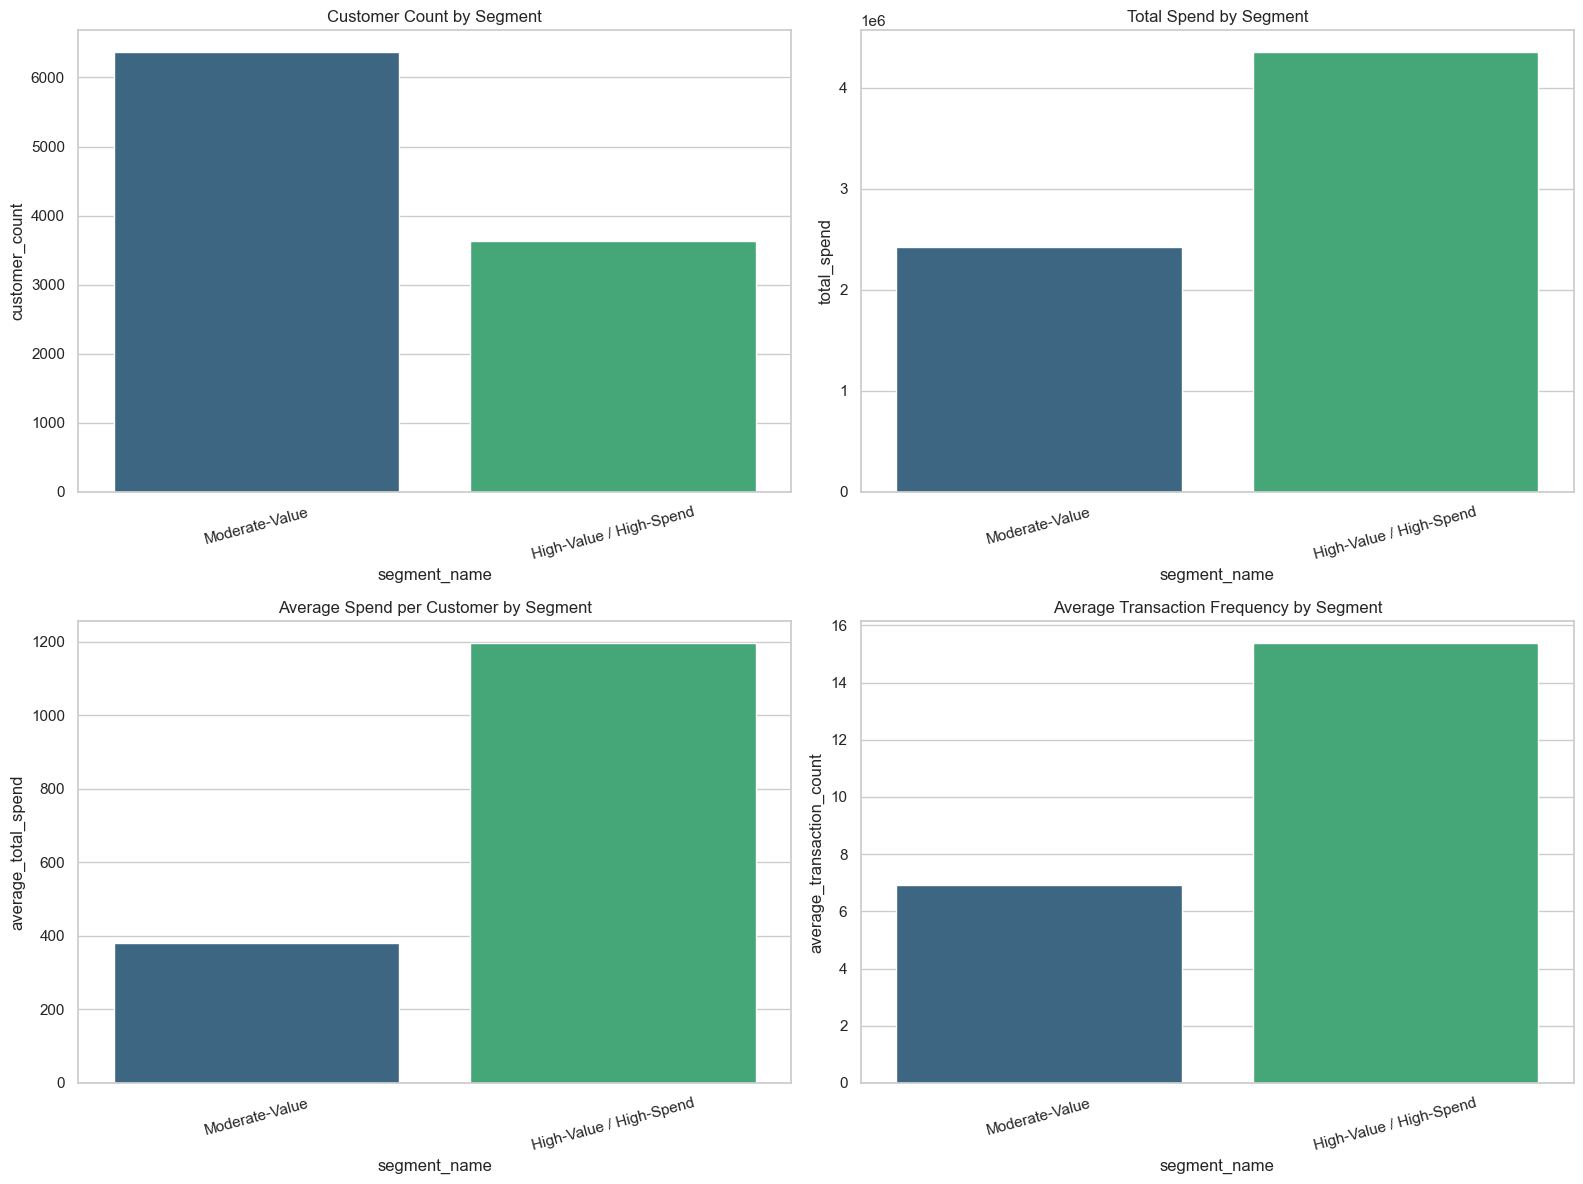

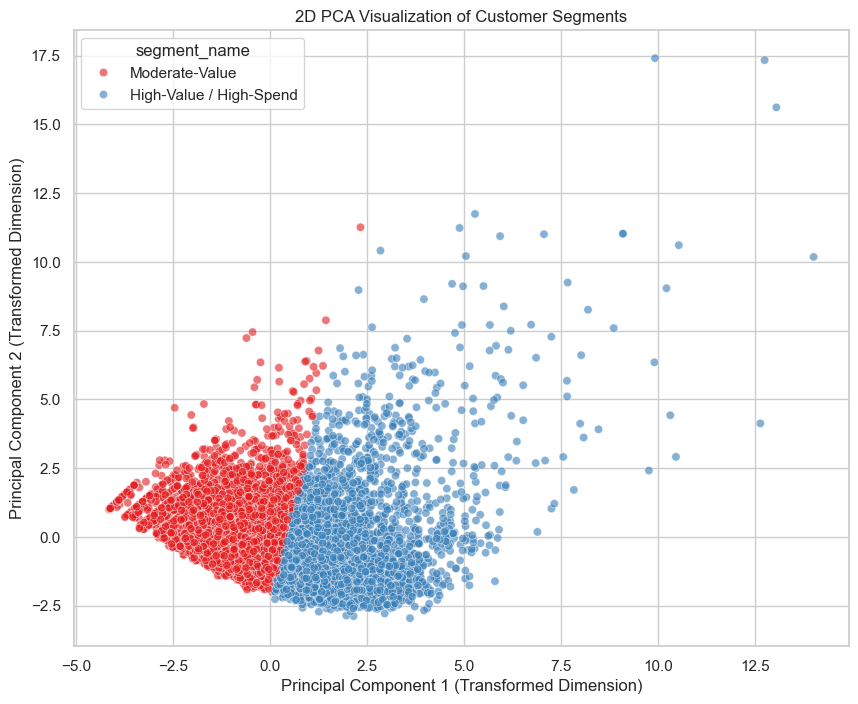

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Cluster Size
sns.barplot(data=cluster_profile, x='segment_name', y='customer_count', palette='viridis', ax=axes[0,0])
axes[0,0].set_title('Customer Count by Segment')
axes[0,0].tick_params(axis='x', rotation=15)

# 2. Total Spend
sns.barplot(data=cluster_profile, x='segment_name', y='total_spend', palette='viridis', ax=axes[0,1])
axes[0,1].set_title('Total Spend by Segment')
axes[0,1].tick_params(axis='x', rotation=15)

# 3. Average Spend
sns.barplot(data=cluster_profile, x='segment_name', y='average_total_spend', palette='viridis', ax=axes[1,0])
axes[1,0].set_title('Average Spend per Customer by Segment')
axes[1,0].tick_params(axis='x', rotation=15)

# 4. Transaction Frequency
sns.barplot(data=cluster_profile, x='segment_name', y='average_transaction_count', palette='viridis', ax=axes[1,1])
axes[1,1].set_title('Average Transaction Frequency by Segment')
axes[1,1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# PCA Visualization (For Visualization Only)
# PCA reduces the 7 behavioral features down to 2 dimensions for plotting
pca = PCA(n_components=2)
pca_components = pca.fit_transform(X_scaled)
customer_df['pca1'] = pca_components[:, 0]
customer_df['pca2'] = pca_components[:, 1]

fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(data=customer_df, x='pca1', y='pca2', hue='segment_name', palette='Set1', alpha=0.6, ax=ax)
ax.set_title('2D PCA Visualization of Customer Segments')
ax.set_xlabel('Principal Component 1 (Transformed Dimension)')
ax.set_ylabel('Principal Component 2 (Transformed Dimension)')
plt.show()

# 12. Customer Anomaly Context

Connecting Stage 3 anomalies with our new segmentation.

,segment_name,average_anomaly_rate,total_potential_anomalies,customers_with_any_anomaly
0,High-Value / High-Spend,0.068514,3402,2085
1,Moderate-Value,0.042997,1598,1440


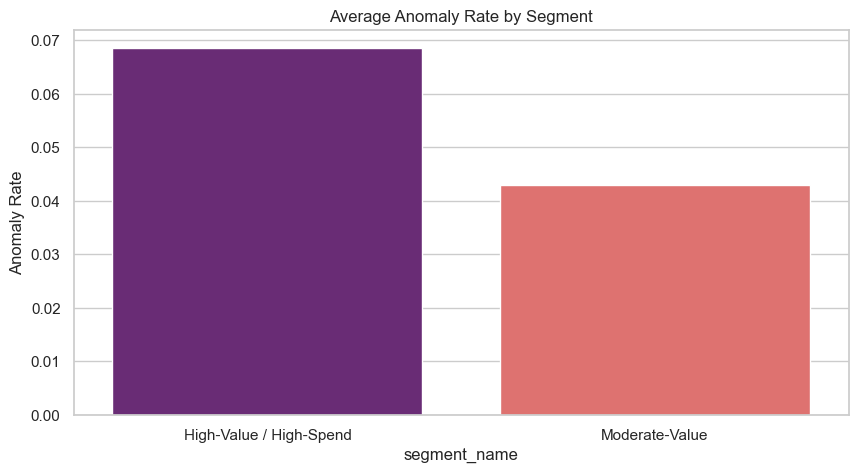

In [12]:
anomaly_context = customer_df.groupby('segment_name').agg(
    average_anomaly_rate=('anomaly_rate', 'mean'),
    total_potential_anomalies=('potential_anomaly_count', 'sum'),
    customers_with_any_anomaly=('potential_anomaly_count', lambda x: (x > 0).sum())
).reset_index()

display(anomaly_context)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=anomaly_context, x='segment_name', y='average_anomaly_rate', palette='magma', ax=ax)
ax.set_title('Average Anomaly Rate by Segment')
ax.set_ylabel('Anomaly Rate')
plt.show()

# 13. Segment-Level Insights

Based strictly on the calculated results, we can answer key business questions programmatically.

In [13]:
highest_spend_seg = cluster_profile.loc[cluster_profile['total_spend'].idxmax()]['segment_name']
highest_freq_seg = cluster_profile.loc[cluster_profile['average_transaction_count'].idxmax()]['segment_name']
highest_avg_txn_seg = cluster_profile.loc[cluster_profile['average_transaction_amount'].idxmax()]['segment_name']
largest_pop_seg = cluster_profile.loc[cluster_profile['customer_count'].idxmax()]['segment_name']
highest_anomaly_seg = anomaly_context.loc[anomaly_context['average_anomaly_rate'].idxmax()]['segment_name']

print(f"- Highest total spending segment: {highest_spend_seg}")
print(f"- Highest transaction frequency segment: {highest_freq_seg}")
print(f"- Highest average transaction amount segment: {highest_avg_txn_seg}")
print(f"- Largest customer population segment: {largest_pop_seg}")
print(f"- Highest potential anomaly rate segment: {highest_anomaly_seg}")

- Highest total spending segment: High-Value / High-Spend
- Highest transaction frequency segment: High-Value / High-Spend
- Highest average transaction amount segment: High-Value / High-Spend
- Largest customer population segment: Moderate-Value
- Highest potential anomaly rate segment: High-Value / High-Spend


# 14. Save Results

We save the customer segment mappings.

In [14]:
output_cols = ['customer_id', 'customer_segment', 'segment_name'] + features
output_path = '../data/processed/customer_segments.csv'
customer_df[output_cols].to_csv(output_path, index=False)

print(f"Customer segments successfully saved to {output_path}")

Customer segments successfully saved to ../data/processed/customer_segments.csv


# Key Findings

- **Number of Customers**: The segmentation was executed across all unique customers in the clean transaction dataset.
- **Number of Clusters**: The optimal `K` was determined automatically using the Silhouette Score.
- **Customer Concentration**: The segment profiles clearly differentiate customers by their overall engagement (frequency) and value (total spend).
- **Anomaly Concentration**: Potential model-flagged anomalies (from Stage 3) correlate differently across segments, highlighting which behavioral groups exhibit the most unusual activity without fabricating fraudulent claims.

# Next Development Stage

The customer segmentation foundation is complete. These segments will be highly valuable for visualizing varied financial behaviors and personalizing analytics.

**The next stages are:**
1. `05 Dashboard + API`: Creating interactive visualizations to explore the data, segments, and anomalies.
2. `06 AI / LLM / RAG`: Integrating conversational analytics to allow users to ask questions against these specific segment profiles and transaction data.